# 14 · GraphSAGE on the patient-similarity networks

Notebook 13 asked how much of the outcome can be read off a stay's own numbers. This notebook adds the network: **GraphSAGE** (`torch_geometric.nn.models.GraphSAGE`) builds each stay's representation from its own features **and the average of its linked stays' representations**, over `layers` hops. So *honest vs cheating network* now acts directly, through who is linked to whom, and not only through derived numbers like node2vec.

**Same protocol as notebook 13**, so every number here can sit next to a linear one: the same patient-grouped 60/20/20 splits (same split seeds), columns standardised with the training stays only, settings and stopping epoch chosen on the validation stays, test stays scored once, repeated over `SEEDS` and reported as mean and spread.

**Three models, to separate what the network adds from what the features already hold:**

| model | what it is |
|---|---|
| `sage` | GraphSAGE on the saved network |
| `mlp` | the *same* architecture and training with **every link removed**. `sage − mlp` on identical splits is what the network adds |
| `sage_nosame` | GraphSAGE with the links between two stays of the **same patient** removed (about a third of links). If a gain needs them, it may be the same person's other admission rather than similar patients |

**Things to know before reading the numbers**

- Full-batch and **transductive**: the whole network is visible during training, but only the *training* stays' outcomes are used. A patient's stays always sit in one split, so a test stay is never linked to its own patient's training stays.
- `GraphSAGE` **ignores edge weights** (`supports_edge_weight` is `False`), so the network enters as present / absent links.
- 6,998 and 3,511 stays are small, so no neighbour sampling is needed.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from ehrgraph.eval.aggregate import write_aggregate  # noqa: F401
from ehrgraph.gnn import graph_sage as G
from ehrgraph.gnn.linear_regressor import YEAR_BANDS
from ehrgraph.gnn.node_features import FEATURE_SETS, LEAKABLE_BLOCKS
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()
nf.apply_style()

TASKS = {"guo_los": "long stay", "new_hypertension": "new high blood pressure"}
NAME = {"safe": "honest", "leaky": "cheating", "null": "random"}
SEEDS = range(5)               # split seeds. Notebook 13 used 10; raise this once the timing looks fine
CONFIGS = G.CONFIGS            # small grid, chosen on the validation stays for every split seed
print("device:", G.pick_device(), "| configs:", len(CONFIGS), "| seeds:", len(SEEDS))

data folder: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/data/omop
results go to: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/results/aggregate
device: cpu | configs: 2 | seeds: 5


## Load the inputs from notebook 12

The same file and the same alignment checks as notebook 13: the prediction year is rebuilt from the labels and checked against the saved outcomes and patients, and a mismatch stops the notebook.

In [6]:
datasets, years = {}, {}
for task in TASKS:
    datasets[task] = torch.load(p.results / f"gnn_inputs_{task}.pt", weights_only=False)

    lab = p.labels(task)
    lab = lab[lab["patient_id"].isin(set(p.diagnoses))].reset_index(drop=True)
    d0 = next(iter(datasets[task].values()))
    assert (lab["value"].astype(int).to_numpy() == d0.y.numpy()).all(), "labels are not aligned with the saved stays"
    assert (pd.factorize(lab["patient_id"])[0] == d0.patient_idx.numpy()).all(), "patients are not aligned"
    years[task] = pd.to_datetime(lab["prediction_time"]).dt.year.to_numpy()
    print(f"{TASKS[task]}: {d0.num_nodes:,} stays, {d0.y.float().mean():.1%} positive, "
          f"{d0.edge_index.shape[1] // 2:,} links, {d0.edge_attr.float().mean():.1%} same-patient, "
          f"{len(datasets[task])} saved combinations")

long stay: 6,998 stays, 25.4% positive, 18,581 links, 37.8% same-patient, 16 saved combinations
new high blood pressure: 3,511 stays, 12.8% positive, 9,787 links, 29.4% same-patient, 16 saved combinations


## Which feature sets and runs

GraphSAGE gets the **diagnosis features** (`dx`), and the **CLMBR** vector when notebook 12 built it. The network-derived feature sets (`n2v`, `structure`) are left out on purpose: they would feed the same network in twice.

- `sage` runs on every saved network (honest, cheating, random) × every feature source (honest or cheating diagnoses).
- `mlp` has no links, so it only needs one run per feature source.
- `sage_nosame` runs on the honest and cheating networks with honest diagnoses.

If CLMBR is present, every run for that question is restricted to the stays that **have** a CLMBR vector, so all models are scored on the same stays.

In [7]:
GNN_FEATURES = [fs for fs in ("dx", "clmbr") if any(k[2] == fs for ds in datasets.values() for k in ds)]

SUBSET = {t: None for t in TASKS}
for t in TASKS:
    d = next((d for k, d in datasets[t].items() if k[2] == "clmbr"), None)
    if d is not None:
        names = list(d.feature_names)
        vec = [i for i, n in enumerate(names) if n != "has_clmbr"]
        has = np.abs(d.x[:, vec].numpy()).sum(1) > 0               # a stay with no CLMBR vector is all zeros
        if not has.all():
            SUBSET[t] = has
        print(f"{TASKS[t]}: CLMBR vector for {has.mean():.1%} of stays" + (" -> restricting every run to them" if SUBSET[t] is not None else ""))

NEEDS_DX = lambda fs: any(b in LEAKABLE_BLOCKS for b in FEATURE_SETS[fs])

def pretty(model, key):
    g, s, fs = key
    parts = [model, fs]
    if model != "mlp":
        parts.append(f"net: {NAME[g]}")
    if NEEDS_DX(fs):
        parts.append(f"feat: {NAME[s]}")
    return " | ".join(parts)

runs = {}
for t, ds in datasets.items():
    r = []
    for fs in GNN_FEATURES:
        ks = [k for k in ds if k[2] == fs and (NEEDS_DX(fs) or k[1] == "safe")]       # the diagnosis source is irrelevant to CLMBR: run it once
        r += [("sage", k) for k in ks]
        r += [("mlp", k) for k in ks if k[0] == "safe"]
        r += [("sage_nosame", k) for k in ks if k[0] in ("safe", "leaky") and k[1] == "safe"]
    runs[t] = r
    print(TASKS[t], len(r), "runs x", len(SEEDS), "seeds")

long stay 9 runs x 5 seeds
new high blood pressure 9 runs x 5 seeds


## Run

A quick timing check first: one run, one seed. Multiply by the number of runs and seeds above to estimate the full cost; lower `SEEDS` or `CONFIGS` if it is too long.

In [8]:
import time
t0 = time.time()
m0, k0 = runs[next(iter(TASKS))][0]
_ = G.evaluate_data(datasets[next(iter(TASKS))][k0], m0, 0, CONFIGS, years[next(iter(TASKS))], SUBSET[next(iter(TASKS))])
one = time.time() - t0
total = sum(len(r) for r in runs.values()) * len(SEEDS) * one
print(f"one run: {one:.1f}s -> about {total / 60:.0f} min for everything (rough: later runs differ in size)")

one run: 2.4s -> about 4 min for everything (rough: later runs differ in size)


In [9]:
res = {t: G.run_models(datasets[t], runs[t], SEEDS, year=years[t], subset=SUBSET[t], configs=CONFIGS, log=lambda s: None) for t in TASKS}

tables = {}
for t in TASKS:
    s = G.summarize(res[t])
    s.index = [pretty(m, (g, so, f)) for m, g, so, f in s.index]
    tables[t] = s
    print(f"{TASKS[t]} - test AUROC, mean and spread over {len(SEEDS)} splits")
    display(s[["mean", "sd", "test_ap", "epoch", "n_features"]].round(3))

long stay - test AUROC, mean and spread over 5 splits


,mean,sd,test_ap,epoch,n_features
mlp | dx | feat: cheating,0.759,0.024,0.501,30.8,65
mlp | dx | feat: honest,0.776,0.014,0.552,50.2,65
sage | dx | net: cheating | feat: cheating,0.752,0.016,0.500,48.8,65
sage | dx | net: cheating | feat: honest,0.759,0.016,0.523,41.4,65
sage | dx | net: random | feat: honest,0.764,0.018,0.535,57.4,65
sage | dx | net: honest | feat: cheating,0.751,0.029,0.500,21.4,65
sage | dx | net: honest | feat: honest,0.768,0.023,0.543,81.2,65
sage_nosame | dx | net: cheating | feat: honest,0.764,0.015,0.537,59.0,65
sage_nosame | dx | net: honest | feat: honest,0.764,0.018,0.535,62.2,65


new high blood pressure - test AUROC, mean and spread over 5 splits


,mean,sd,test_ap,epoch,n_features
mlp | dx | feat: cheating,0.896,0.020,0.546,58.8,65
mlp | dx | feat: honest,0.673,0.034,0.255,41.0,65
sage | dx | net: cheating | feat: cheating,0.880,0.025,0.526,77.4,65
sage | dx | net: cheating | feat: honest,0.681,0.051,0.286,33.4,65
sage | dx | net: random | feat: honest,0.626,0.042,0.218,45.2,65
sage | dx | net: honest | feat: cheating,0.882,0.022,0.529,118.4,65
sage | dx | net: honest | feat: honest,0.668,0.055,0.250,51.4,65
sage_nosame | dx | net: cheating | feat: honest,0.686,0.034,0.282,21.4,65
sage_nosame | dx | net: honest | feat: honest,0.659,0.029,0.241,45.8,65


`epoch` is the average stopping epoch (the epoch with the best validation AUROC). Values near the maximum of 200 mean training was still improving; values under about 10 mean the model peaked almost immediately and is probably just reading the features.

### Which settings were chosen

In [10]:
for t in TASKS:
    print(TASKS[t])
    display(res[t].groupby("model")[["hidden", "dropout", "weight_decay"]].agg(lambda s: s.value_counts().to_dict()))

long stay


,hidden,dropout,weight_decay
model,,,
mlp,{64: 10},"{0.2: 6, 0.5: 4}","{0.01: 6, 0.001: 4}"
sage,{64: 25},"{0.2: 15, 0.5: 10}","{0.01: 15, 0.001: 10}"
sage_nosame,{64: 10},"{0.2: 7, 0.5: 3}","{0.01: 7, 0.001: 3}"


new high blood pressure


,hidden,dropout,weight_decay
model,,,
mlp,{64: 10},"{0.2: 6, 0.5: 4}","{0.01: 6, 0.001: 4}"
sage,{64: 25},"{0.2: 18, 0.5: 7}","{0.01: 18, 0.001: 7}"
sage_nosame,{64: 10},"{0.2: 7, 0.5: 3}","{0.01: 7, 0.001: 3}"


## The questions we care about

Each row is a **paired difference** in test AUROC (A minus B) on identical splits, so split luck cancels. `fraction_a_higher` is the share of splits where A won. A difference smaller than its `sd` is not a finding.

Read the first block for **what the network adds**, the second for **whether cheating changes anything**.

In [11]:
H = ("safe", "safe", "dx")           # honest network, honest diagnoses
PAIRS = [
    # --- what does the network add? (same features, links on vs off)
    ("network adds, honest net:  sage - mlp",                    ("sage", *H),                       ("mlp", *H)),
    ("network adds, cheating net:  sage - mlp",                  ("sage", "leaky", "safe", "dx"),    ("mlp", *H)),
    ("network adds, random net:  sage - mlp",                    ("sage", "null", "safe", "dx"),     ("mlp", *H)),
    ("real vs random network (sage)",                            ("sage", *H),                       ("sage", "null", "safe", "dx")),
    ("without same-patient links:  sage_nosame - mlp",           ("sage_nosame", *H),                ("mlp", *H)),
    ("same-patient links matter?  sage - sage_nosame",          ("sage", *H),                       ("sage_nosame", *H)),
    # --- does cheating change anything?
    ("cheating network vs honest (sage, honest dx)",             ("sage", "leaky", "safe", "dx"),    ("sage", *H)),
    ("cheating diagnoses vs honest (sage, honest net)",          ("sage", "safe", "leaky", "dx"),    ("sage", *H)),
    ("both cheat vs both honest (sage)",                         ("sage", "leaky", "leaky", "dx"),   ("sage", *H)),
    ("cheating diagnoses vs honest (mlp, no network)",           ("mlp", "safe", "leaky", "dx"),     ("mlp", *H)),
    # --- CLMBR (only if notebook 12 built it)
    ("CLMBR vs diagnoses (sage, honest net)",                    ("sage", "safe", "safe", "clmbr"),  ("sage", *H)),
    ("network adds to CLMBR:  sage - mlp",                       ("sage", "safe", "safe", "clmbr"),  ("mlp", "safe", "safe", "clmbr")),
]
out = []
for t in TASKS:
    have = {tuple(r) for r in res[t][G.KEY].drop_duplicates().to_numpy()}
    for name, a, b in PAIRS:
        if a in have and b in have:
            out.append({"question": TASKS[t], "A minus B": name, **G.paired(res[t], a, b)})
if out:
    display(pd.DataFrame(out).set_index(["question", "A minus B"]).round(3))
else:
    print("none of these comparisons were run")

mean_diff  \
question                A minus B                                                    
long stay               network adds, honest net:  sage - mlp               -0.008   
                        network adds, cheating net:  sage - mlp             -0.017   
                        network adds, random net:  sage - mlp               -0.012   
                        real vs random network (sage)                        0.004   
                        without same-patient links:  sage_nosame - mlp      -0.012   
                        same-patient links matter?  sage - sage_nosame       0.004   
                        cheating network vs honest (sage, honest dx)        -0.009   
                        cheating diagnoses vs honest (sage, honest net)     -0.017   
                        both cheat vs both honest (sage)                    -0.016   
                        cheating diagnoses vs honest (mlp, no network)      -0.018   
new high blood pressure network adds, honest net:  sage - mlp               -0.005   
                        network adds, cheating net:  sage - mlp              0.008   
                        network adds, random net:  sage - mlp               -0.048   
                        real vs random network (sage)                        0.042   
                        without same-patient links:  sage_nosame - mlp      -0.015   
                        same-patient links matter?  sage - sage_nosame       0.009   
                        cheating network vs honest (sage, honest dx)         0.013   
                        cheating diagnoses vs honest (sage, honest net)      0.214   
                        both cheat vs both honest (sage)                     0.212   
                        cheating diagnoses vs honest (mlp, no network)       0.222   

                                                                            sd  \
question                A minus B                                                
long stay               network adds, honest net:  sage - mlp            0.016   
                        network adds, cheating net:  sage - mlp          0.014   
                        network adds, random net:  sage - mlp            0.010   
                        real vs random network (sage)                    0.010   
                        without same-patient links:  sage_nosame - mlp   0.011   
                        same-patient links matter?  sage - sage_nosame   0.007   
                        cheating network vs honest (sage, honest dx)     0.013   
                        cheating diagnoses vs honest (sage, honest net)  0.029   
                        both cheat vs both honest (sage)                 0.024   
                        cheating diagnoses vs honest (mlp, no network)   0.022   
new high blood pressure network adds, honest net:  sage - mlp            0.033   
                        network adds, cheating net:  sage - mlp          0.040   
                        network adds, random net:  sage - mlp            0.044   
                        real vs random network (sage)                    0.054   
                        without same-patient links:  sage_nosame - mlp   0.010   
                        same-patient links matter?  sage - sage_nosame   0.039   
                        cheating network vs honest (sage, honest dx)     0.029   
                        cheating diagnoses vs honest (sage, honest net)  0.048   
                        both cheat vs both honest (sage)                 0.066   
                        cheating diagnoses vs honest (mlp, no network)   0.036   

                                                                         n_seeds  \
question                A minus B                                                  
long stay               network adds, honest net:  sage - mlp                  5   
                        network adds, cheating net:  sage - mlp                5   
                        network adds, r

## Against the linear baseline from notebook 13

GraphSAGE minus the linear model on the **same diagnosis features and the same splits**. Only shown for seeds both notebooks ran, and not for questions restricted to a CLMBR subset (their splits differ). A GraphSAGE that does not beat the linear row is not earning its complexity.

In [12]:
LIN = p.results / "linear_baselines.csv"
if not LIN.exists():
    print("run notebook 13 first (linear_baselines.csv not found)")
else:
    lin = pd.read_csv(LIN)
    rows = []
    for t in TASKS:
        if SUBSET[t] is not None:
            continue
        L = lin[lin["question"] == TASKS[t]]
        for m, g, so, fs in res[t][G.KEY].drop_duplicates().itertuples(index=False):
            lrow = L[(L.graph == "safe") & (L.source == so) & (L.feature_set == fs)].set_index("seed")["test_auc"]
            srow = res[t][(res[t].model == m) & (res[t].graph == g) & (res[t].source == so) & (res[t].feature_set == fs)].set_index("seed")["test_auc"]
            d = (srow - lrow).dropna()
            if len(d):
                rows.append({"question": TASKS[t], "model": pretty(m, (g, so, fs)), "mean_diff": d.mean(), "sd": d.std(), "n_seeds": len(d),
                             "fraction_higher": float((d > 0).mean())})
    if rows:
        display(pd.DataFrame(rows).set_index(["question", "model"]).round(3))
    else:
        print("nothing to compare: every question is restricted to a CLMBR subset, so its splits differ from notebook 13's")

mean_diff  \
question                model                                                        
long stay               sage | dx | net: honest | feat: honest               0.021   
                        sage | dx | net: honest | feat: cheating            -0.003   
                        sage | dx | net: cheating | feat: honest             0.012   
                        sage | dx | net: cheating | feat: cheating          -0.002   
                        sage | dx | net: random | feat: honest               0.017   
                        mlp | dx | feat: honest                              0.029   
                        mlp | dx | feat: cheating                            0.004   
                        sage_nosame | dx | net: honest | feat: honest        0.017   
                        sage_nosame | dx | net: cheating | feat: honest      0.017   
new high blood pressure sage | dx | net: honest | feat: honest               0.074   
                        sage | dx | net: honest | feat: cheating             0.030   
                        sage | dx | net: cheating | feat: honest             0.087   
                        sage | dx | net: cheating | feat: cheating           0.028   
                        sage | dx | net: random | feat: honest               0.031   
                        mlp | dx | feat: honest                              0.079   
                        mlp | dx | feat: cheating                            0.044   
                        sage_nosame | dx | net: honest | feat: honest        0.065   
                        sage_nosame | dx | net: cheating | feat: honest      0.091   

                                                                            sd  \
question                model                                                    
long stay               sage | dx | net: honest | feat: honest           0.010   
                        sage | dx | net: honest | feat: cheating         0.017   
                        sage | dx | net: cheating | feat: honest         0.009   
                        sage | dx | net: cheating | feat: cheating       0.017   
                        sage | dx | net: random | feat: honest           0.015   
                        mlp | dx | feat: honest                          0.016   
                        mlp | dx | feat: cheating                        0.017   
                        sage_nosame | dx | net: honest | feat: honest    0.011   
                        sage_nosame | dx | net: cheating | feat: honest  0.011   
new high blood pressure sage | dx | net: honest | feat: honest           0.047   
                        sage | dx | net: honest | feat: cheating         0.023   
                        sage | dx | net: cheating | feat: honest         0.036   
                        sage | dx | net: cheating | feat: cheating       0.020   
                        sage | dx | net: random | feat: honest           0.037   
                        mlp | dx | feat: honest                          0.030   
                        mlp | dx | feat: cheating                        0.020   
                        sage_nosame | dx | net: honest | feat: honest    0.024   
                        sage_nosame | dx | net: cheating | feat: honest  0.032   

                                                                         n_seeds  \
question                model                                                      
long stay               sage | dx | net: honest | feat: honest                 5   
                        sage | dx | net: honest | feat: cheating               5   
                        sage | dx | net: cheating | feat: honest               5   
                        sage | dx | net: cheating | feat: cheating             5   
                        sage | dx | net: random | feat: honest                 5   
                        mlp | dx | feat: honest                                5   
                        mlp | dx | feat

## Year-adjusted view

Test AUROC **within** calendar-year bands (2015 is the coding switch). A model that wins only by learning the calendar will not keep its score here. Bands with fewer than 10 positive or 10 negative test stays are left blank, so blood-pressure bands are noisy.

In [13]:
band_cols = [f"auc_{b}" for b in YEAR_BANDS]
for t in TASKS:
    df = res[t].copy()
    df["run"] = [pretty(m, (g, s, f)) for m, g, s, f in zip(df.model, df.graph, df.source, df.feature_set)]
    print(TASKS[t]); display(df.groupby("run")[["test_auc", *band_cols]].mean().round(3))

long stay


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
run,,,,
mlp | dx | feat: cheating,0.759,0.719,0.795,0.788
mlp | dx | feat: honest,0.776,0.749,0.799,0.804
sage | dx | net: cheating | feat: cheating,0.752,0.712,0.782,0.782
sage | dx | net: cheating | feat: honest,0.759,0.745,0.775,0.767
sage | dx | net: honest | feat: cheating,0.751,0.714,0.777,0.783
sage | dx | net: honest | feat: honest,0.768,0.745,0.787,0.785
sage | dx | net: random | feat: honest,0.764,0.743,0.780,0.787
sage_nosame | dx | net: cheating | feat: honest,0.764,0.744,0.780,0.782
sage_nosame | dx | net: honest | feat: honest,0.764,0.741,0.782,0.788


new high blood pressure


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
run,,,,
mlp | dx | feat: cheating,0.896,0.863,0.903,0.925
mlp | dx | feat: honest,0.673,0.608,0.744,0.678
sage | dx | net: cheating | feat: cheating,0.880,0.848,0.865,0.915
sage | dx | net: cheating | feat: honest,0.681,0.650,0.705,0.614
sage | dx | net: honest | feat: cheating,0.882,0.851,0.890,0.901
sage | dx | net: honest | feat: honest,0.668,0.608,0.729,0.659
sage | dx | net: random | feat: honest,0.626,0.579,0.684,0.590
sage_nosame | dx | net: cheating | feat: honest,0.686,0.627,0.696,0.709
sage_nosame | dx | net: honest | feat: honest,0.659,0.602,0.677,0.681


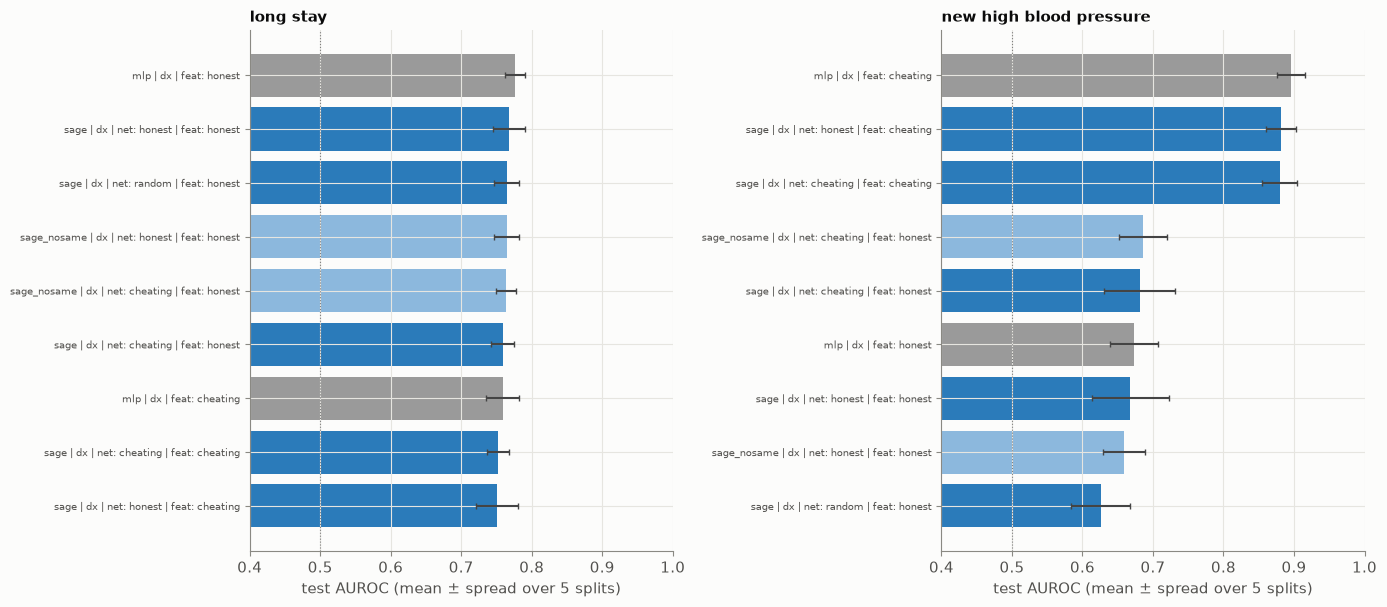

In [14]:
COLOR = {"sage": "#2b7bba", "mlp": "#9a9a9a", "sage_nosame": "#8cb8dd"}
fig, axes = plt.subplots(1, len(TASKS), figsize=(14, 6.2), sharex=False)
for ax, t in zip(np.atleast_1d(axes), TASKS):
    s = tables[t].sort_values("mean")
    ax.barh(s.index, s["mean"], xerr=s["sd"], color=[COLOR[i.split(" | ")[0]] for i in s.index], ecolor="#444", capsize=2)
    ax.axvline(0.5, color="grey", lw=0.8, ls=":"); ax.set_xlim(0.4, 1.0)
    ax.set_title(TASKS[t]); ax.set_xlabel(f"test AUROC (mean ± spread over {len(SEEDS)} splits)")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
nf.save(fig, p.figures / "14_graphsage.png")
plt.show()

In [15]:
# aggregate numbers only (no patient data)
pd.concat({TASKS[t]: res[t] for t in TASKS}, names=["question"]).reset_index(level=0) \
  .to_csv(p.results / "graphsage_results.csv", index=False)

## What we learned

*(fill in after running)*

- **Does the network help at all?** `sage − mlp` on the honest network, per question. If it is within its spread of zero, GraphSAGE is just reading each stay's own features.
- **Is it the network, or just having a graph?** `sage` on the real network vs the random one. The random network should not help; if it does, the gain is not about patient similarity.
- **Same-patient links.** `sage − sage_nosame`. A large drop means a lot of the gain is a patient's own other admissions.
- **Does cheating show up?** Cheating *diagnoses* should lift blood pressure (the future record contains the diagnosis, notebook 03) and not long stay (notebook 02). Does a cheating *network* change anything once the features are honest?
- **Against the linear baseline.** Does GraphSAGE beat logistic regression on the same features and splits?
- **Year.** Does any model's score survive within year bands, or collapse toward the year-only score from notebook 13?
- **CLMBR** (only if `CLMBR_PATH` was set in notebook 12): CLMBR vs diagnoses, and whether the network adds to CLMBR.

## Read these results carefully

- **Transductive.** Test stays' features, and their links to training stays, take part in message passing. No test outcome is used, so this is not label leakage; it is the intended use of a fixed network.
- **Possible time leak in same-patient links.** A link to a patient's *later* stay brings in that stay's record. `sage_nosame` shows how much the result depends on same-patient links at all; the earlier-vs-later check from notebook 12 decides whether those links are honest in time.
- **Calendar year.** Year alone scores about 0.64 on blood pressure, so a model near that has learned little else.
- **Selection on validation.** Settings and stopping epoch come from the validation stays, which makes the validation score slightly optimistic. The test score is untouched by that.
- **Small positive counts.** Blood pressure has about 90 positive test stays, so differences of a point or two are noise. Prefer the paired table to eyeballing the bars.
- **Next:** GCN and GAT are one-line swaps in `gnn_train.fit_one` (same `torch_geometric.nn.models` interface) and will share these splits.